In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

In [2]:
df = pd.read_csv("Food_Delivery_Time_Prediction.csv")

print(df.head())

  Order_ID       Customer_Location     Restaurant_Location  Distance  \
0  ORD0001  (17.030479, 79.743077)  (12.358515, 85.100083)      1.57   
1  ORD0002  (15.398319, 86.639122)  (14.174874, 77.025606)     21.32   
2  ORD0003  (15.687342, 83.888808)  (19.594748, 82.048482)      6.95   
3  ORD0004  (20.415599, 78.046984)  (16.915906, 78.278698)     13.79   
4  ORD0005  (14.786904, 78.706532)  (15.206038, 86.203182)      6.72   

  Weather_Conditions Traffic_Conditions  Delivery_Person_Experience  \
0              Rainy             Medium                           4   
1             Cloudy             Medium                           8   
2              Snowy             Medium                           9   
3             Cloudy                Low                           2   
4              Rainy               High                           6   

  Order_Priority Order_Time Vehicle_Type  Restaurant_Rating  Customer_Rating  \
0         Medium  Afternoon          Car                4.1 

In [3]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
print(df.info())

Rows and columns: (200, 15)

Column names:
['Order_ID', 'Customer_Location', 'Restaurant_Location', 'Distance', 'Weather_Conditions', 'Traffic_Conditions', 'Delivery_Person_Experience', 'Order_Priority', 'Order_Time', 'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time', 'Order_Cost', 'Tip_Amount']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    200 non-null    str    
 1   Customer_Location           200 non-null    str    
 2   Restaurant_Location         200 non-null    str    
 3   Distance                    200 non-null    float64
 4   Weather_Conditions          200 non-null    str    
 5   Traffic_Conditions          200 non-null    str    
 6   Delivery_Person_Experience  200 non-null    int64  
 7   Order_Priority              200 non-null    str

In [4]:
print(df.isnull().sum())

Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64


In [5]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (200, 15)


In [6]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [7]:
cat_cols = [
    "Customer_Location",
    "Restaurant_Location",
    "Weather_Conditions",
    "Traffic_Conditions",
    "Order_Priority",
    "Order_Time",
    "Vehicle_Type"
]

In [8]:
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [9]:
print(df.isnull().sum())

Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64


In [10]:
df["Delivery_Status"] = np.where(
    df["Delivery_Time"] > 30,
    1,
    0
)

In [11]:
print(df["Delivery_Status"].value_counts())

Delivery_Status
1    174
0     26
Name: count, dtype: int64


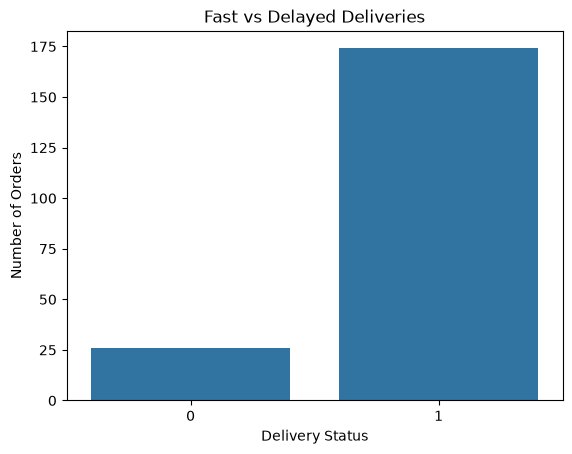

In [12]:
sns.countplot(x="Delivery_Status", data=df)

plt.title("Fast vs Delayed Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.show()

In [13]:
df["Customer_Latitude"] = df["Customer_Location"].str.extract(
    r"\(([-\d.]+),"
).astype(float)

df["Customer_Longitude"] = df["Customer_Location"].str.extract(
    r",\s*([-\d.]+)\)"
).astype(float)

df["Restaurant_Latitude"] = df["Restaurant_Location"].str.extract(
    r"\(([-\d.]+),"
).astype(float)

df["Restaurant_Longitude"] = df["Restaurant_Location"].str.extract(
    r",\s*([-\d.]+)\)"
).astype(float)

In [14]:
print(
    df[
        [
            "Customer_Latitude",
            "Customer_Longitude",
            "Restaurant_Latitude",
            "Restaurant_Longitude"
        ]
    ].head()
)

   Customer_Latitude  Customer_Longitude  Restaurant_Latitude  \
0          17.030479           79.743077            12.358515   
1          15.398319           86.639122            14.174874   
2          15.687342           83.888808            19.594748   
3          20.415599           78.046984            16.915906   
4          14.786904           78.706532            15.206038   

   Restaurant_Longitude  
0             85.100083  
1             77.025606  
2             82.048482  
3             78.278698  
4             86.203182  


In [15]:
from math import radians, sin, cos, sqrt, atan2

def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2) ** 2 + \
        cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2

    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return R * c

In [16]:
df["Calculated_Distance"] = df.apply(
    lambda row: haversine_distance(
        row["Customer_Latitude"],
        row["Customer_Longitude"],
        row["Restaurant_Latitude"],
        row["Restaurant_Longitude"]
    ),
    axis=1
)

In [17]:
print(
    df[
        ["Distance", "Calculated_Distance"]
    ].head()
)

   Distance  Calculated_Distance
0      1.57           775.651198
1     21.32          1042.385597
2      6.95           476.220706
3     13.79           389.912629
4      6.72           806.505886


In [18]:
df = df.drop(
    [
        "Order_ID",
        "Customer_Location",
        "Restaurant_Location",
        "Delivery_Time",
        "Calculated_Distance",
        "Customer_Latitude",
        "Customer_Longitude",
        "Restaurant_Latitude",
        "Restaurant_Longitude"
    ],
    axis=1
)

In [19]:
from sklearn.preprocessing import LabelEncoder

cat_cols = [
    "Weather_Conditions",
    "Traffic_Conditions",
    "Order_Priority",
    "Order_Time",
    "Vehicle_Type"
]

encoder = LabelEncoder()

for col in cat_cols:
    df[col] = encoder.fit_transform(df[col])

In [20]:
print(df.head())

   Distance  Weather_Conditions  Traffic_Conditions  \
0      1.57                   1                   2   
1     21.32                   0                   2   
2      6.95                   2                   2   
3     13.79                   0                   1   
4      6.72                   1                   0   

   Delivery_Person_Experience  Order_Priority  Order_Time  Vehicle_Type  \
0                           4               2           0             2   
1                           8               1           3             2   
2                           9               0           3             1   
3                           2               2           1             1   
4                           6               1           3             1   

   Restaurant_Rating  Customer_Rating  Order_Cost  Tip_Amount  Delivery_Status  
0                4.1              3.0     1321.10       81.54                0  
1                4.5              4.2      152.21       

In [21]:
X = df.drop("Delivery_Status", axis=1)
y = df["Delivery_Status"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

nb_prediction = nb_model.predict(X_test_scaled)

In [25]:
nb_accuracy = accuracy_score(y_test, nb_prediction)
nb_precision = precision_score(y_test, nb_prediction)
nb_recall = recall_score(y_test, nb_prediction)
nb_f1 = f1_score(y_test, nb_prediction)

print("Naive Bayes Results")
print("-------------------")
print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1 Score :", nb_f1)

Naive Bayes Results
-------------------
Accuracy : 0.875
Precision: 0.875
Recall   : 1.0
F1 Score : 0.9333333333333333


In [26]:
print("Actual classes:")
print(np.unique(y_test, return_counts=True))

print("\nPredicted classes:")
print(np.unique(nb_prediction, return_counts=True))

Actual classes:
(array([0, 1]), array([ 5, 35]))

Predicted classes:
(array([1]), array([40]))


In [27]:
print(classification_report(
    y_test,
    nb_prediction,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.88      1.00      0.93        35

    accuracy                           0.88        40
   macro avg       0.44      0.50      0.47        40
weighted avg       0.77      0.88      0.82        40



In [28]:
k_values = range(1, 21)
k_scores = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn,
        X_train_scaled,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    k_scores.append(scores.mean())

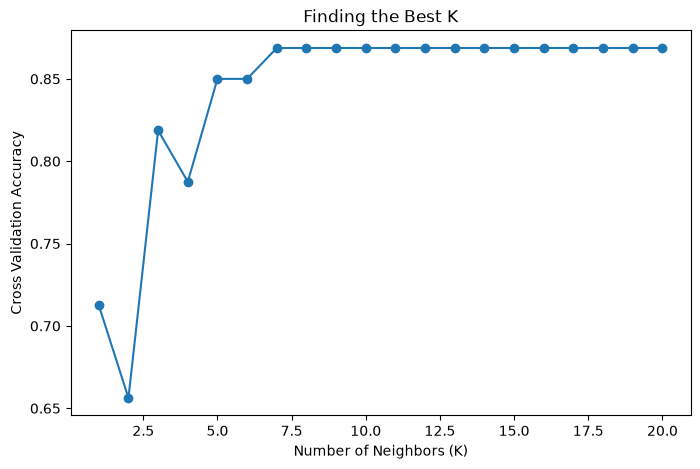

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, k_scores, marker="o")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Cross Validation Accuracy")
plt.title("Finding the Best K")

plt.show()

In [30]:
best_k = k_values[np.argmax(k_scores)]

print("Best K:", best_k)

Best K: 7


In [31]:
knn_model = KNeighborsClassifier(
    n_neighbors=best_k
)

knn_model.fit(X_train_scaled, y_train)

knn_prediction = knn_model.predict(X_test_scaled)

In [32]:
knn_accuracy = accuracy_score(y_test, knn_prediction)
knn_precision = precision_score(y_test, knn_prediction, zero_division=0)
knn_recall = recall_score(y_test, knn_prediction, zero_division=0)
knn_f1 = f1_score(y_test, knn_prediction, zero_division=0)

print("KNN Results")
print("-----------")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1 Score :", knn_f1)

KNN Results
-----------
Accuracy : 0.875
Precision: 0.875
Recall   : 1.0
F1 Score : 0.9333333333333333


In [33]:
depths = range(2, 16)
tree_scores = []

for depth in depths:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_split=5,
        random_state=42
    )

    scores = cross_val_score(
        tree,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    tree_scores.append(scores.mean())

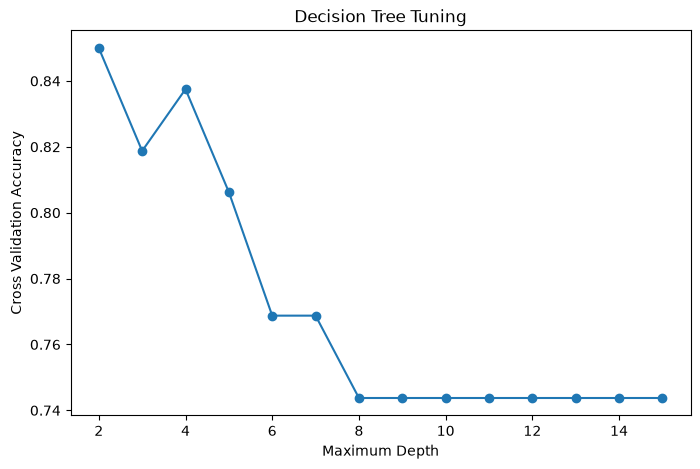

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(depths, tree_scores, marker="o")

plt.xlabel("Maximum Depth")
plt.ylabel("Cross Validation Accuracy")
plt.title("Decision Tree Tuning")

plt.show()

In [35]:
best_depth = depths[np.argmax(tree_scores)]

print("Best Depth:", best_depth)

Best Depth: 2


In [36]:
tree_model = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_split=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_prediction = tree_model.predict(X_test)

In [37]:
tree_accuracy = accuracy_score(y_test, tree_prediction)
tree_precision = precision_score(y_test, tree_prediction, zero_division=0)
tree_recall = recall_score(y_test, tree_prediction, zero_division=0)
tree_f1 = f1_score(y_test, tree_prediction, zero_division=0)

print("Decision Tree Results")
print("--------------------")
print("Accuracy :", tree_accuracy)
print("Precision:", tree_precision)
print("Recall   :", tree_recall)
print("F1 Score :", tree_f1)

Decision Tree Results
--------------------
Accuracy : 0.85
Precision: 0.8717948717948718
Recall   : 0.9714285714285714
F1 Score : 0.918918918918919


In [38]:
print(classification_report(
    y_test,
    tree_prediction,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.87      0.97      0.92        35

    accuracy                           0.85        40
   macro avg       0.44      0.49      0.46        40
weighted avg       0.76      0.85      0.80        40



In [39]:
results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "KNN",
        "Decision Tree"
    ],
    "Accuracy": [
        nb_accuracy,
        knn_accuracy,
        tree_accuracy
    ],
    "Precision": [
        nb_precision,
        knn_precision,
        tree_precision
    ],
    "Recall": [
        nb_recall,
        knn_recall,
        tree_recall
    ],
    "F1 Score": [
        nb_f1,
        knn_f1,
        tree_f1
    ]
})

print(results)

           Model  Accuracy  Precision    Recall  F1 Score
0    Naive Bayes     0.875   0.875000  1.000000  0.933333
1            KNN     0.875   0.875000  1.000000  0.933333
2  Decision Tree     0.850   0.871795  0.971429  0.918919


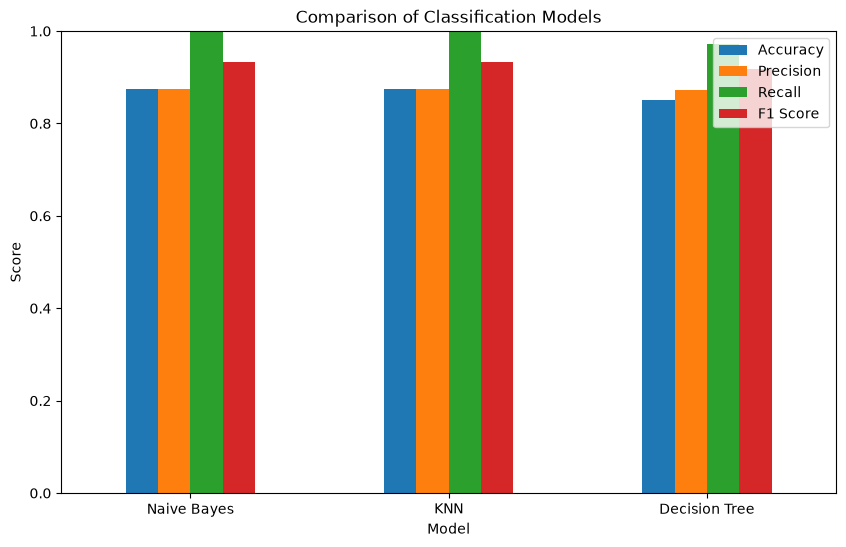

In [41]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend()

plt.show()

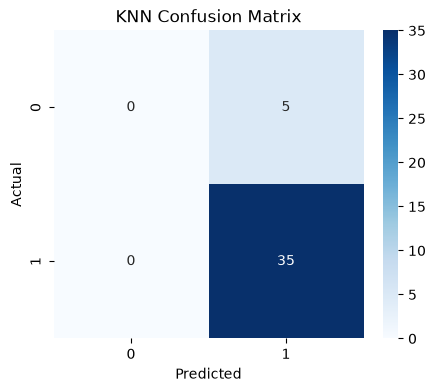

In [42]:
cm_knn = confusion_matrix(y_test, knn_prediction)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

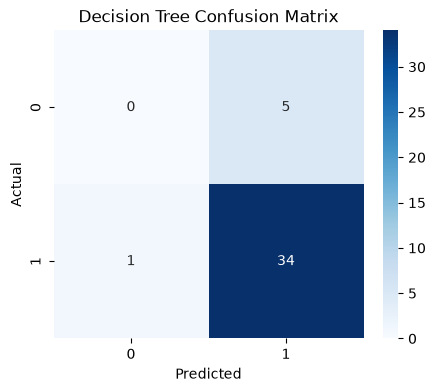

In [43]:
cm_tree = confusion_matrix(y_test, tree_prediction)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [44]:
nb_probability = nb_model.predict_proba(
    X_test_scaled
)[:, 1]

knn_probability = knn_model.predict_proba(
    X_test_scaled
)[:, 1]

tree_probability = tree_model.predict_proba(
    X_test
)[:, 1]

In [45]:
fpr_nb, tpr_nb, _ = roc_curve(
    y_test,
    nb_probability
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test,
    knn_probability
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    tree_probability
)

In [46]:
auc_nb = roc_auc_score(
    y_test,
    nb_probability
)

auc_knn = roc_auc_score(
    y_test,
    knn_probability
)

auc_tree = roc_auc_score(
    y_test,
    tree_probability
)

print("Naive Bayes AUC :", auc_nb)
print("KNN AUC         :", auc_knn)
print("Decision Tree AUC:", auc_tree)

Naive Bayes AUC : 0.3771428571428571
KNN AUC         : 0.5314285714285715
Decision Tree AUC: 0.4742857142857143


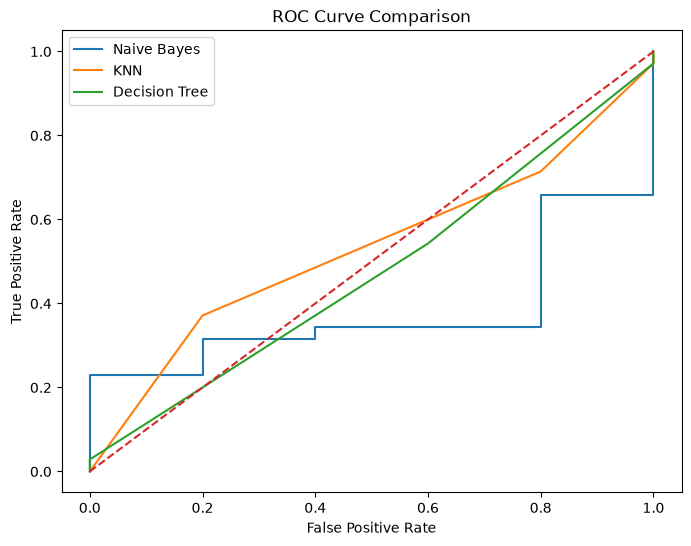

In [47]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_nb,
    tpr_nb,
    label="Naive Bayes"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label="KNN"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label="Decision Tree"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

In [48]:
importance = pd.Series(
    tree_model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(
    ascending=False
)

print(importance)

Customer_Rating               0.515470
Restaurant_Rating             0.291291
Tip_Amount                    0.193239
Traffic_Conditions            0.000000
Weather_Conditions            0.000000
Distance                      0.000000
Delivery_Person_Experience    0.000000
Vehicle_Type                  0.000000
Order_Time                    0.000000
Order_Priority                0.000000
Order_Cost                    0.000000
dtype: float64


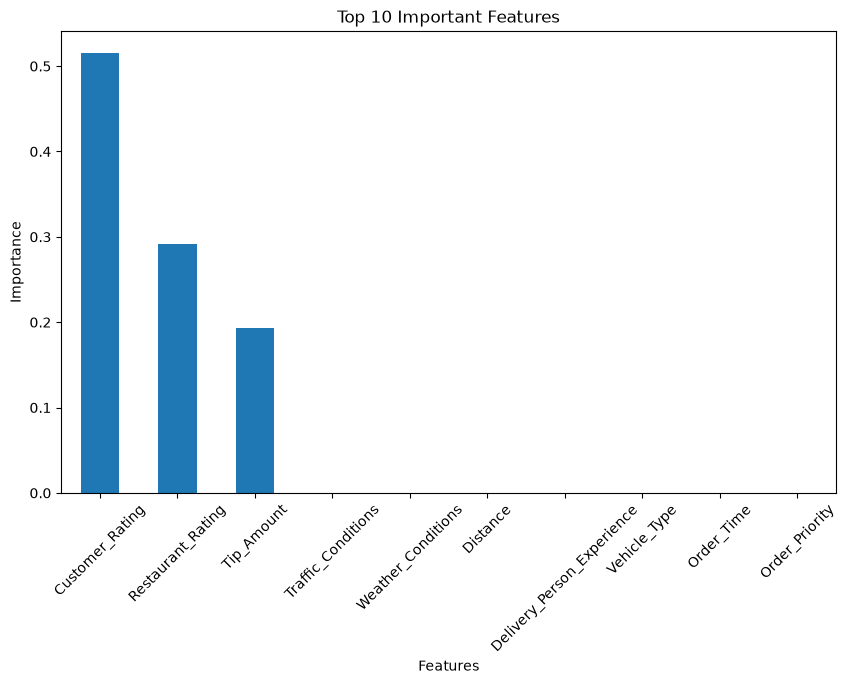

In [49]:
plt.figure(figsize=(10, 6))

importance.head(10).plot(
    kind="bar"
)

plt.title("Top 10 Important Features")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.xticks(rotation=45)

plt.show()

In [50]:
auc_results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "KNN",
        "Decision Tree"
    ],
    "AUC": [
        auc_nb,
        auc_knn,
        auc_tree
    ]
})

print(auc_results)

           Model       AUC
0    Naive Bayes  0.377143
1            KNN  0.531429
2  Decision Tree  0.474286


## Model Analysis

In this project, we used three machine learning models: Naive Bayes, KNN, and Decision Tree. We compared the models using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.

The results show that the models perform differently for Fast and Delayed deliveries. The dataset has more Delayed orders than Fast orders, so accuracy alone cannot give a complete idea about the model performance.

Because of this, we also looked at the confusion matrix, F1-score, and ROC-AUC while comparing the models.


## Strengths and Limitations

### Naive Bayes

**Strengths:**

* Simple and fast to train.
* Easy to implement.

**Limitations:**

* It has difficulty identifying Fast deliveries.
* The class imbalance affects its performance.

### KNN

**Strengths:**

* Simple and easy to understand.
* K was selected using cross-validation.
* Scaling was applied before using the model.

**Limitations:**

* Its performance is affected by class imbalance.
* It can take more time when the dataset becomes large.

### Decision Tree

**Strengths:**

* Easy to understand and interpret.
* It does not require feature scaling.
* It gives feature importance, which helps us understand the model.

**Limitations:**

* It can be affected by the training data.
* It also has difficulty identifying the Fast class.


## Actionable Insights

From the results, we can make a few observations:

1. Most of the orders in the dataset are Delayed, while Fast orders are much fewer.

2. The models have difficulty identifying Fast deliveries correctly.

3. The Decision Tree feature-importance graph shows which features were used more by the trained model.

4. Having more Fast delivery examples in the dataset could help the models learn that class better.

5. In the future, more useful information about traffic, weather, distance, and delivery conditions can be added to improve the prediction.


## Conclusion

In this project, we used machine learning to predict whether a food delivery would be Fast or Delayed. The dataset was first cleaned by handling missing values and removing duplicate records. Location information was also used to calculate the distance between the customer and restaurant.

Three models were used for prediction: Naive Bayes, KNN, and Decision Tree. The models were evaluated using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.

The results showed that the models achieved good accuracy, but they had difficulty identifying Fast deliveries. This is mainly because the dataset contains many more Delayed orders than Fast orders. Therefore, accuracy alone does not give a complete picture of the model performance.

The project helped us understand how machine learning can be applied to food delivery data and also showed the importance of handling imbalanced data and using different evaluation metrics. In the future, the model can be improved by using more Fast-delivery data, additional delivery-related features, and class-balancing techniques.
